# Datensatz Cityscapes
## Key Figures
### Classes
- 30 Classes in total
- {category: classes}
  - flat: road, sidewalk, parking, ...
  - human: person, rider (a person on a bycicle, motorcycle, scooter, ...)
  - vehicle: car, truck, bus, motorcycle, bycicle, ...
  - construction: building, wall, fence, ...
  - object: pole, traffic sign and traffic light (without their pole), ...
  - nature: vegetation (vertical vegetation), terrain (horizontal vegetation)
  - sky: sky
  - void: ground, ...
### Properties
- 5,000 fine annotated images
  - from 27 cities (mostly german cities)
- 20,000 coarse annoted images (could potentially be used for pretraining or as data augmentation)
  - from 50 cities (mostly german cities)
- different seasons (spring, summer, fall)
- at daytime
- good/medium weather conditions
- manually selected images with varying scene layouts and backgrounds

<img src="../visualization/images/cityscapesCities.jpg" alt="Cityscapes Cities" style="height:500px;"/>

### Data
- gtFine: 
  - fine annotations for training and validation set (3475 annotated images)
    - 2975 for train
    - 500 for val
  - dummy annotations for testing set (1525 black images)
    - 1525 for val
    - ignore regions with rgb(0, 0, 0)
    - because it is an open benchmark dataset
- leftImg8bit: rgb images for training, validation and testing set (5000 images)
  - 2975 for train
  - 1525 for test
  - 500 for val
  
- vehicle: gps-coordinates (lat, lon), vehicle alignment and speed, ... for train, val and test set (5000 json files)

In [1]:
import numpy as np
import pandas as pd
from pathlib import Path
import cv2
from tqdm import tqdm
import matplotlib.pyplot as plt

def get_num_cities(data_path, ignore_dummys=False):
    label_path = data_path / "gtFine_trainvaltest/gtFine"
    num_cities = 0

    split_paths = list(label_path.glob("*"))
    if ignore_dummys:
        split_paths.remove((label_path / "test"))

    for split_path in split_paths:
        cities = list(split_path.glob("*"))
        num_cities += len(cities)

    return num_cities


def get_num_imgs_per_split_and_city(data_path, ignore_dummys=False):
    img_counts_per_split_and_city = dict()

    image_path = data_path / "leftImg8bit_trainvaltest/leftImg8bit"
    split_paths = list(image_path.glob("*"))
    if ignore_dummys:
        split_paths.remove((image_path / "test"))

    for split_path in split_paths:
        # make sure inner dictionary exists
        img_counts_per_split_and_city.setdefault(split_path.name, {})

        cities = list(split_path.glob("*"))
        for city in cities:
            images = list(city.glob("*.png"))
            img_counts_per_split_and_city[split_path.name][city.name] = len(images)

    return img_counts_per_split_and_city

def get_img_size(data_path):
    image_path = data_path / "leftImg8bit_trainvaltest/leftImg8bit"
    split_paths = list(image_path.glob("*"))

    # load 1 sample image from the first city of every split
    for split_path in split_paths:
        cities = list(split_path.glob("*"))
        sample_img_path = list(cities[0].glob("*.png"))[0]
        
        sample_img = cv2.imread(str(sample_img_path))
        height, width, channels = sample_img.shape
        print(f"Size of sample image: {width}x{height}x{channels} (Width, Height, Channels); Sampled from {split_path.name}/{cities[0].name}")

def get_class_dist_for_city_rgb(data_path, city):
    # skip test split because it has no annotations (only dummy images)
    splits = ["train", "val"]
    label_path = data_path / "gtFine_trainvaltest/gtFine"
    class_dict = dict()

    for split in splits:
        city_path = label_path / split / city
        if city_path.exists():
            print(f'The city {city.capitalize()} has annotations in "{str(city_path)}"')
            
            img_paths = list(city_path.glob("*color.png"))
            for img_path in tqdm(img_paths, total=len(img_paths), desc=f"Processing images in {city}", unit="image"):
                img = cv2.imread(str(img_path))
                img = cv2.cvtColor(img, cv2.COLOR_BGR2RGB)

                # row-wise rgb values of pixels
                rgb_values = img.reshape(-1, 3)
                unique_rgb_values, counts = np.unique(rgb_values, axis=0, return_counts=True)

                for rgb, count in zip(unique_rgb_values, counts):
                    rgb_tuple = tuple(rgb)
                    if rgb_tuple not in class_dict:
                        class_dict[rgb_tuple] = 0
                    class_dict[rgb_tuple] += count

        else:
            print(f"No annotations found for {city} in {split}")

    return class_dict

In [13]:
def get_class_dist_for_city(data_path, city, label_type="labelIds", verbose=True, splits = ["train", "val"]):
    # skip test split because it has no annotations (only dummy images)
    label_path = data_path / "gtFine_trainvaltest/gtFine"
    class_dict = dict()

    for split in splits:
        city_path = label_path / split / city
        if city_path.exists():
            if verbose:
                print(f'The city {city.capitalize()} has annotations in "{str(city_path)}"')

            label_id_paths = list(city_path.glob(f"*{label_type}.png"))
            for label_id_path in tqdm(label_id_paths, total=len(label_id_paths), desc=f"Processing {label_type} in {city}", unit="image"):
                img = cv2.imread(str(label_id_path), cv2.IMREAD_UNCHANGED)

                # flatten image and count unique label ids
                label_ids, counts = np.unique(img.reshape(-1), return_counts=True)

                for label_id, count in zip(label_ids, counts):
                    class_dict[label_id] = class_dict.get(label_id, 0) + count
                    
        else:
            if verbose:
                print(f"No annotations found for {city} in {split}")
    
    return class_dict

def get_class_dist_for_dataset(data_path, label_type="labelIds", splits = ["train", "val"]):
    label_path = data_path / "gtFine_trainvaltest/gtFine"
    class_dict = dict()

    for split in splits:
        city_paths = list((label_path / split).glob("*"))
        cities = [city_path.name for city_path in city_paths]
        
        for city in cities:
            city_dist = get_class_dist_for_city(data_path, city, label_type=label_type, verbose=False, splits=[split])

            # merge city dicts into global dict
            for label_id, count in city_dist.items():
                class_dict[label_id] = class_dict.get(label_id, 0) + count

    return class_dict

In [3]:
data_path = Path("../data/Cityscapes")

# Number of cities
print(f"Number of cities in total: {get_num_cities(data_path)}")
print(f"Number of cities with fine annotations: {get_num_cities(data_path, ignore_dummys=True)}")

# Number of images per split
img_counts = get_num_imgs_per_split_and_city(data_path)

splits = list(img_counts.keys())
counts = [sum(img_counts[split].values()) for split in splits]

for split, count in zip(splits, counts):
    print(f"Number of images in {split}: {count}")

# Sample image size
get_img_size(data_path)

Number of cities in total: 27
Number of cities with fine annotations: 21
Number of images in test: 1525
Number of images in train: 2975
Number of images in val: 500
Size of sample image: 2048x1024x3 (Width, Height, Channels); Sampled from test/berlin
Size of sample image: 2048x1024x3 (Width, Height, Channels); Sampled from train/aachen
Size of sample image: 2048x1024x3 (Width, Height, Channels); Sampled from val/frankfurt


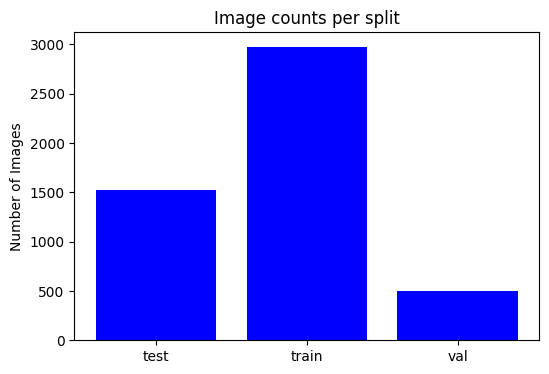

In [5]:
plt.figure(figsize=(6,4))
plt.bar(splits, counts, color="blue")
plt.ylabel("Number of Images")
plt.title("Image counts per split")
plt.show()

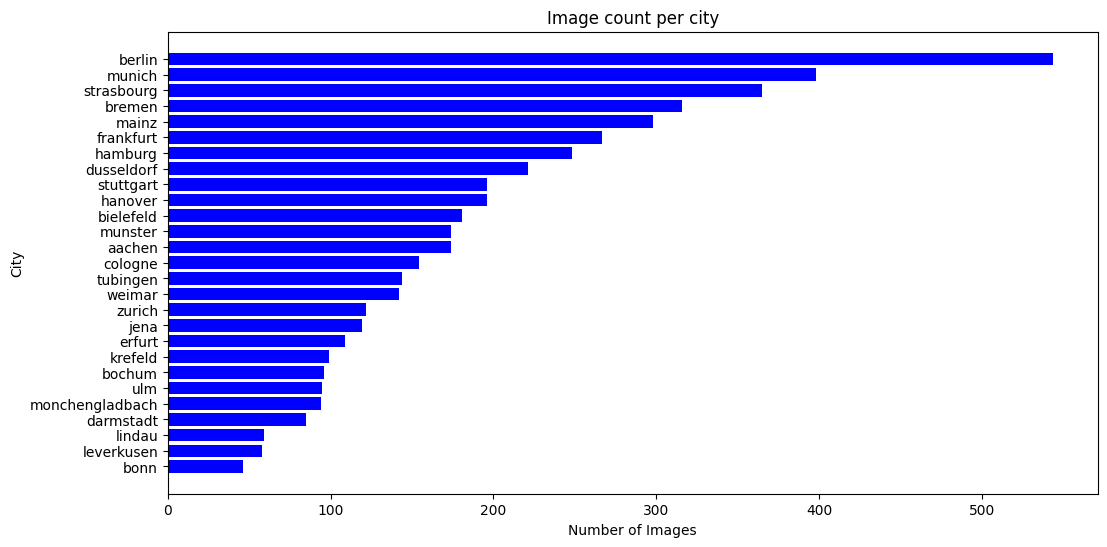

In [4]:
image_counts = get_num_imgs_per_split_and_city(data_path, ignore_dummys=False)
city_counts = dict()

for sub_dict in image_counts.values():
    for city, count in sub_dict.items():
        if city not in city_counts:
            city_counts[city] = 0
        city_counts[city] += count

sorted_cities_counts = sorted(city_counts.items(), key=lambda x: x[1])
cities = [c for c, _ in sorted_cities_counts]
counts = [cnt for _, cnt in sorted_cities_counts]

plt.figure(figsize=(12, 6))
plt.barh(cities, counts, color="blue")
plt.xlabel("Number of Images")
plt.ylabel("City")
plt.title("Image count per city")
plt.show()

Processing labelIds in munster: 100%|██████████| 174/174 [00:04<00:00, 39.80image/s]


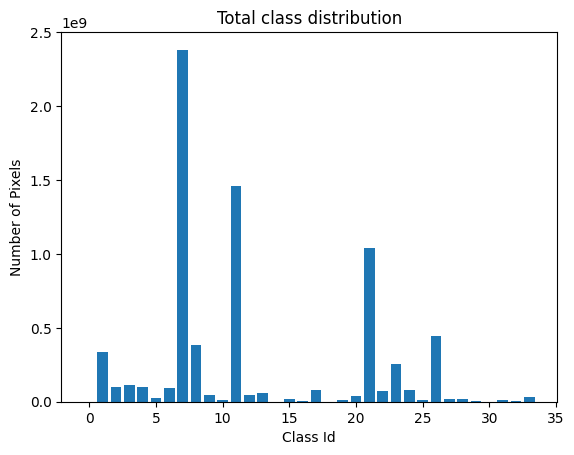

In [ ]:
data_path = Path("../data/Cityscapes")
class_dict_total = get_class_dist_for_dataset(data_path)

# Sort by id
sorted_items = sorted(class_dict_total.items(), key=lambda x: x[0])
labels, counts = zip(*sorted_items)

plt.bar(labels, counts)
plt.title("Total class distribution")
plt.xlabel("Class Id")
plt.ylabel("Number of Pixels")
plt.show()


Processing labelTrainIds in zurich: 100%|██████████| 122/122 [00:03<00:00, 40.33image/s]


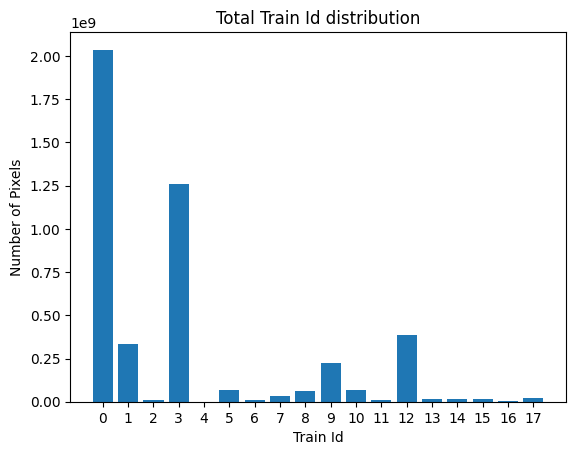

In [14]:
data_path = Path("../data/Cityscapes")
class_dict_total = get_class_dist_for_dataset(data_path, label_type="labelTrainIds", splits=["train"])

# Sort by id
sorted_items = sorted(class_dict_total.items(), key=lambda x: x[0])
sorted_items = sorted_items[:-1]    # drop last element (trainId=255)
labels, counts = zip(*sorted_items)

plt.bar(labels, counts)
plt.title("Total Train Id distribution")
plt.xlabel("Train Id")
plt.ylabel("Number of Pixels")
plt.xticks(labels)
plt.show()

Processing labelIds in aachen:   0%|          | 0/54 [00:00<?, ?image/s]

Processing labelIds in zurich: 100%|██████████| 51/51 [00:01<00:00, 31.56image/s]


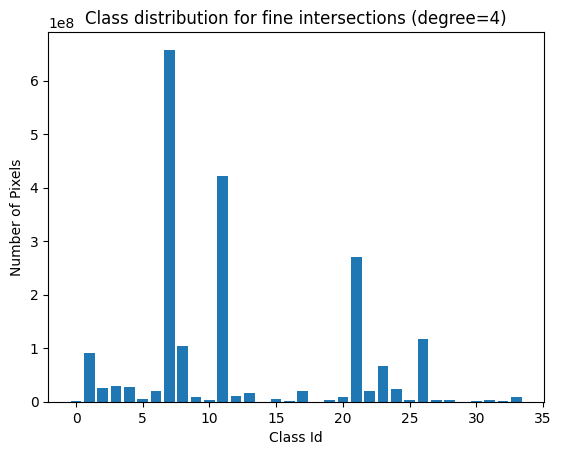

In [15]:
data_path = Path("../data/cityscapes_intersections/fine_intersections_3")
class_dict_fine_intersections_3 = get_class_dist_for_dataset(data_path, splits=["train"])

# Sort by id
sorted_items = sorted(class_dict_fine_intersections_3.items(), key=lambda x: x[0])
labels, counts = zip(*sorted_items)

plt.bar(labels, counts)
plt.title("Class distribution for fine intersections (degree=4)")
plt.xlabel("Class Id")
plt.ylabel("Number of Pixels")
plt.show()

Processing labelTrainIds in zurich: 100%|██████████| 51/51 [00:01<00:00, 29.60image/s]


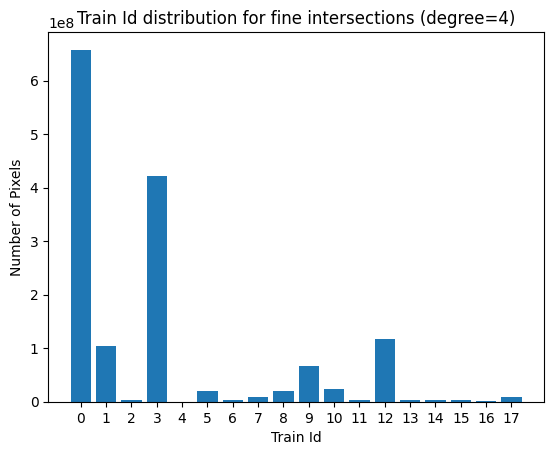

In [16]:
data_path = Path("../data/cityscapes_intersections/fine_intersections_3")
class_dict_fine_intersections_3 = get_class_dist_for_dataset(data_path, label_type="labelTrainIds", splits=["train"])

# Sort by id
sorted_items = sorted(class_dict_fine_intersections_3.items(), key=lambda x: x[0])
sorted_items = sorted_items[:-1]    # drop last element (trainId=255)
labels, counts = zip(*sorted_items)

plt.bar(labels, counts)
plt.title("Train Id distribution for fine intersections (degree=4)")
plt.xlabel("Train Id")
plt.ylabel("Number of Pixels")
plt.xticks(labels)
plt.show()

In [18]:
def calculate_class_weights(class_dist, method="median_freq_balancing"):
    num_classes = len(class_dist) - 1  # exclude void class

    total_pixels = sum(class_dist.values())
    class_weights = np.zeros(num_classes)

    if method == "median_freq_balancing":
        freqs = np.zeros(num_classes)

        for class_id, pixel_count in class_dist.items():
            if class_id != 255:  # ignore void class
                freqs[class_id] = pixel_count / total_pixels

        median_freq = np.median(freqs)

        for class_id in range(num_classes):
            if freqs[class_id] > 0:
                class_weights[class_id] = median_freq / freqs[class_id]
            else:
                class_weights[class_id] = 0.0

    return class_weights

class_weights = calculate_class_weights(class_dict_total, method="median_freq_balancing")
print(f"Class Weights (Median Frequency Balancing): {class_weights}")

class_weights_fine_3 = calculate_class_weights(class_dict_fine_intersections_3, method="median_freq_balancing")
print(f"Class Weights for fine intersections (degree=3) (Median Frequency Balancing): {class_weights_fine_3}")

Class Weights (Median Frequency Balancing): [1.31065087e-02 7.94136840e-02 2.37443038e+00 2.11827327e-02
 4.87447283e+01 3.93771135e-01 2.31847399e+00 8.74323718e-01
 4.17187520e-01 1.20498389e-01 3.97091699e-01 3.58439574e+00
 6.90434726e-02 1.80612387e+00 2.05339280e+00 2.07444225e+00
 4.90008880e+00 1.16787112e+00]
Class Weights for fine intersections (degree=3) (Median Frequency Balancing): [1.36438819e-02 8.68164661e-02 3.38649071e+00 2.12464778e-02
 2.74959390e+03 4.36793239e-01 2.40902856e+00 9.49572788e-01
 4.66163412e-01 1.33985798e-01 3.75906061e-01 3.62556420e+00
 7.70869409e-02 2.52694198e+00 2.51998002e+00 2.97834820e+00
 6.47761767e+00 1.05608348e+00]


### References
- https://www.cityscapes-dataset.com/downloads/
- https://www.cityscapes-dataset.com/dataset-overview/#features